/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.3442 - loss: 2.1387 - val_accuracy: 0.5051 - val_loss: 1.5095
Epoch 2/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6335 - loss: 1.1529 - val_accuracy: 0.7007 - val_loss: 0.9169
Epoch 3/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7451 - loss: 0.7951 - val_accuracy: 0.8001 - val_loss: 0.6231
Epoch 4/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8143 - loss: 0.5763 - val_accuracy: 0.7968 - val_loss: 0.5823
Epoch 5/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8617 - loss: 0.4326 - val_accuracy: 0.8784 - val_loss: 0.3532
Epoch 6/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8959 - loss: 0.3319 - val_accuracy: 0.9177 - val_loss: 0.2683
Epoch 7/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9289 - loss: 0.2379 - val_accuracy: 0.9395 - val_loss: 0.1983
Epoch 8/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9482 - loss: 0.1811 - val_accuracy: 0.

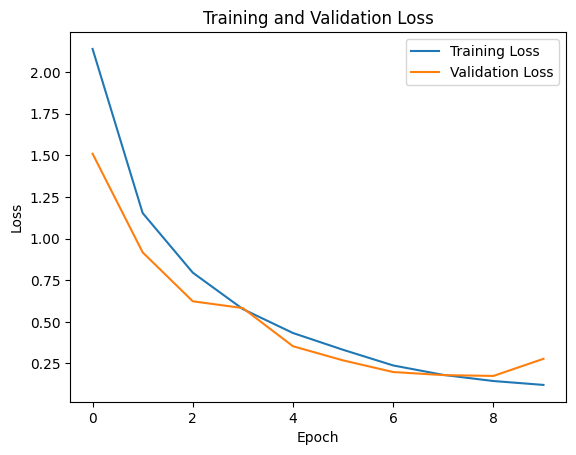

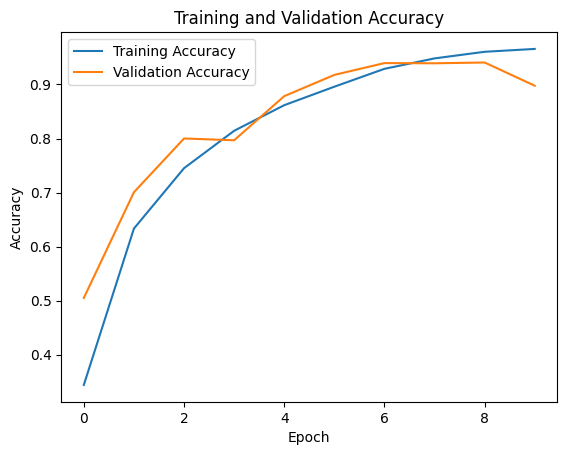

In [12]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
# 2. Load data
train = pd.read_csv('/content/sign_mnist_train.csv')
test = pd.read_csv('/content/sign_mnist_test.csv')
X_train = train.drop('label', axis=1).values / 255.0
y_train = train['label'].values
X_test = test.drop('label', axis=1).values / 255.0
y_test = test['label'].values
# Fix missing pixel values
X_train = np.nan_to_num(X_train)
X_test = np.nan_to_num(X_test)
# 3. Build model
model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(25, activation='softmax')
])
# 4. Compile and train
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=10,
                    validation_split=0.1, batch_size=32)
# 5. Evaluate
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy * 100, "%")
# 6. Plot loss and accuracy
# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()